In [34]:
from langgraph.graph import StateGraph , START , END
from typing import TypedDict

In [35]:
class BMIInput(TypedDict):
    weight: float
    height: float
    result: float
    bmi_category: str

In [36]:
def calculate_bmi(state: BMIInput) -> BMIInput:
    """Calculate BMI given weight in kilograms and height in meters."""
    weight = state['weight']
    height = state['height']
    bmi = weight / (height ** 2)
    state['result'] = round(bmi, 2)
    return state

In [37]:
def BMI_category(state: BMIInput) -> BMIInput:
    """Determine BMI category based on the calculated BMI."""
    bmi = state['result']
    if bmi < 18.5:
        state['bmi_category'] = 'Underweight'
    elif 18.5 <= bmi < 24.9:
        state['bmi_category'] = 'Normal weight'
    elif 25 <= bmi < 29.9:
        state['bmi_category'] = 'Overweight'
    else:
        state['bmi_category'] = 'Obesity'
    return state

In [38]:
graph = StateGraph(BMIInput)
graph.add_node("calculate_bmi" , calculate_bmi)
graph.add_node("BMI_category" , BMI_category)

graph.add_edge(START , "calculate_bmi")
graph.add_edge("calculate_bmi" , "BMI_category")
graph.add_edge("BMI_category" , END)

workflow = graph.compile()

In [39]:
initial_state = {'weight': 62, 'height': 1.75}
final_state = workflow.invoke(initial_state)
print(final_state)

{'weight': 62, 'height': 1.75, 'result': 20.24, 'bmi_category': 'Normal weight'}


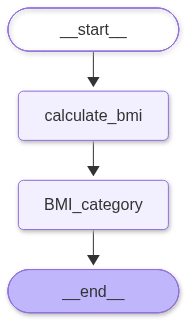

In [40]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())